In [1]:
import tensorflow as tf
import tensorflow.keras as keras
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['SimHei']

In [2]:
defaults = [tf.float32,tf.float32,tf.int32]

In [3]:
trainData = tf.data.experimental.CsvDataset(['./data/train.csv'],defaults,header=True)
evalData = tf.data.experimental.CsvDataset(['./data/eval.csv'],defaults,header=True)

In [4]:
def parseCSV(*vals):
    col_names = ['leftEye','rightEye','isTired']
    features = dict(zip(col_names,vals[:-1]))
    labels = vals[-1]
    return features,labels

In [5]:
# 分割成特征向量 x 和输出值 y
trainData = trainData.map(parseCSV).batch(32)
evalData = evalData.map(parseCSV).batch(32)

In [6]:
feature_columns = []

In [7]:
for header in ['leftEye','rightEye']:
    feature_columns.append(tf.feature_column.numeric_column(header))

In [8]:
model = keras.Sequential()

In [9]:
feature_layer = tf.keras.layers.DenseFeatures(feature_columns)

In [10]:
model.add(feature_layer)
model.add(keras.layers.Dense(128,activation='relu'))
model.add(keras.layers.Dense(64,activation='relu'))
model.add(keras.layers.Dense(1,activation='sigmoid'))

In [11]:
adam = keras.optimizers.Adam(0.0001)

In [12]:
model.compile(
    optimizer=adam,
    loss=tf.keras.losses.binary_crossentropy,
    metrics=['accuracy'])

In [13]:
history = model.fit(trainData,validation_data=evalData,epochs=200)

Epoch 1/200


     47/Unknown - 2s 4ms/step - loss: 0.6928 - accuracy: 0.5306WARNING:tensorflow:Layers in a Sequential model should only have a single input tensor. Received: inputs={'leftEye': <tf.Tensor 'IteratorGetNext:0' shape=(None,) dtype=float32>, 'rightEye': <tf.Tensor 'IteratorGetNext:1' shape=(None,) dtype=float32>}. Consider rewriting this model with the Functional API.
56/56 [==============================] - 2s 18ms/step - loss: 0.6927 - accuracy: 0.5356 - val_loss: 0.6922 - val_accuracy: 0.5483
Epoch 2/200
56/56 [==============================] - 0s 4ms/step - loss: 0.6918 - accuracy: 0.5508 - val_loss: 0.6914 - val_accuracy: 0.5483
Epoch 3/200
56/56 [==============================] - 0s 4ms/step - loss: 0.6909 - accuracy: 0.5508 - val_loss: 0.6905 - val_accuracy: 0.5483
Epoch 4/200
56/56 [==============================] - 0s 4ms/step - loss: 0.6900 - accuracy: 0.5508 - val_loss: 0.6898 - val_accuracy: 0.5483
Epoch 5/200
56/56 [==============================] - 0s 4ms/step - loss: 0.68

In [14]:
tf.keras.models.save_model(model,"./model/keras_nn")

INFO:tensorflow:Assets written to: ./model/keras_nn\assets


INFO:tensorflow:Assets written to: ./model/keras_nn\assets


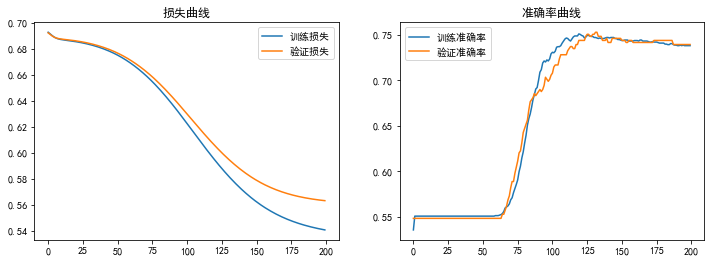

In [15]:
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='训练损失')
plt.plot(history.history['val_loss'], label='验证损失')
plt.title('损失曲线')
plt.legend()
plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='训练准确率')
plt.plot(history.history['val_accuracy'], label='验证准确率')
plt.title('准确率曲线')
plt.legend()
plt.show()